# Monolithic MDO: Multidisciplinary Feasible (MDF) vs. Individual Discipline Feasible (IDF)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L11/L11_monolithic_mdo_mdf_idf.ipynb)
### MECH 559 - Systems Optimization - L11
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Monolithic MDO* section of the lecture. In the MDA notebook the
design was fixed. Now we **optimize** the running example with a single optimizer, using the
two monolithic formulations from the slides:

- **MDF**: the optimizer sees only the design $\mathbf{x}$; every evaluation runs a converged
  MDA, so every iterate is consistent.
- **IDF**: the optimizer also chooses **target** coupling variables $\mathbf{u}^t$ and enforces
  consistency through equality constraints; each discipline runs **once** per evaluation.

We solve both with a gradient-based optimizer (SLSQP) and a derivative-free one (OMADS, as in
the L10 notebooks), then compare them on the numbers that matter: objective, consistency,
discipline evaluations and robustness.

## Learning objectives

1. Implement MDF and IDF for a coupled problem and explain what each optimizer "sees".
2. Verify that MDF and IDF have the **same optimum**, and explain why a solver may stop at
   different points.
3. Count the real cost of each formulation in **discipline evaluations**.
4. Show why IDF is more robust than MDF when the MDA can fail.
5. Recognize a modelling pitfall: an MDA with several solutions and an unbounded branch.

In [1]:
import contextlib
import io
import tempfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, NonlinearConstraint
from OMADS import mads

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"mdf": "#1D5FA8", "idf": "#D1495B", "ref": "#EDAE49"}
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
POST_DIR = tempfile.mkdtemp(prefix="omads_post_")     # OMADS writes logs here; keep the course folder clean

---
## 1. The problem and its disciplines

$$
\begin{aligned}
\min_{\mathbf{x} = [u, v, w]^\mathrm{T}} \quad & f = u + v + a + b \\
\text{subject to} \quad & g = w + b - 10 \le 0, \qquad 0 < u, v, w \le 10 \\
\text{where} \quad & a = \mathcal{U}_1(u, v; b) = \log u + \log v + \log b, \qquad
                     b = \mathcal{U}_2(u, w; a) = u^{-1} + w^{-1} + a^{-1}
\end{aligned}
$$

Each discipline is wrapped in a small class that **counts its own evaluations**, so we can
measure the cost of each formulation honestly.

In [2]:
class Discipline:
    """A discipline analysis that counts how many times it is run."""

    def __init__(self, func, name):
        self.func, self.name, self.calls = func, name, 0

    def __call__(self, *args):
        self.calls += 1
        return self.func(*args)


D1 = Discipline(lambda u, v, b: np.log(u) + np.log(v) + np.log(b), "aerodynamics-like (a)")
D2 = Discipline(lambda u, w, a: 1.0 / u + 1.0 / w + 1.0 / a, "structures-like (b)")


def reset_counters():
    D1.calls = D2.calls = 0


LB, UB = np.full(3, 1e-3), np.full(3, 10.0)
X0 = np.array([1.0, 1.0, 1.0])

---
## 2. MDF: the optimizer only sees $\mathbf{x}$

$$
\min_{\mathbf{x}}\ f\big(\mathbf{x}, \hat{\mathbf{u}}(\mathbf{x})\big)
\quad \text{s.t.} \quad g\big(\mathbf{x}, \hat{\mathbf{u}}(\mathbf{x})\big) \le 0,
\qquad \hat{\mathbf{u}}(\mathbf{x}) \text{ from a converged MDA.}
$$

We use the Newton MDA from the previous notebook (analytic Jacobian), started from the last
converged coupling variables (a **warm start**). If the MDA fails to converge, the function
raises, and the caller decides what to do with the failure.

One safeguard needs explaining up front: this MDA has a **second, non-physical solution**
with $\hat a < 0$ (Section 6 shows it, and what goes wrong if you ignore it). Our Newton MDA
therefore **damps** any step that would make $\hat a$ or $\hat b$ non-positive (it halves the
step until both stay positive), which keeps it on the physical branch. If the warm start
fails, the evaluator retries from a fixed cold start.

In [3]:
class MDAFailure(Exception):
    pass


def newton_mda(x, u0=(1.0, 1.0), tol=1e-10, max_iter=60, keep_positive=True):
    """Newton MDA. keep_positive=True halves any step that would make a or b non-positive,
    which keeps the iterates on the physical branch (a > 0)."""
    u, v, w = x
    a, b = u0
    for _ in range(max_iter):
        r = np.array([a - D1(u, v, b), b - D2(u, w, a)])
        if not np.all(np.isfinite(r)):
            raise MDAFailure("non-finite residual")
        if np.linalg.norm(r) < tol:
            return np.array([a, b])
        J = np.array([[1.0, -1.0 / b], [1.0 / a ** 2, 1.0]])
        step = np.linalg.solve(J, -r)
        if keep_positive:
            while a + step[0] <= 0 or b + step[1] <= 0:
                step = step / 2
        a, b = np.array([a, b]) + step
        if b <= 0:
            raise MDAFailure("b <= 0: log(b) undefined")
    raise MDAFailure("Newton MDA did not converge")


class MDF:
    """MDF evaluator: x -> (f, g), running a warm-started Newton MDA at each call."""

    COLD_START = (1.0, 4.5)

    def __init__(self, physical_branch_only=True):
        self.u_last = np.array(self.COLD_START)
        self.physical_branch_only = physical_branch_only
        self.failures = 0
        self.cache = {}

    def solve_mda(self, x):
        if not self.physical_branch_only:                # plain Newton: return whatever it finds
            return newton_mda(x, self.u_last, keep_positive=False)
        try:
            return newton_mda(x, self.u_last)
        except (MDAFailure, np.linalg.LinAlgError, FloatingPointError):
            return newton_mda(x, self.COLD_START)       # retry from a fixed cold start

    def coupling(self, x):
        key = tuple(np.round(x, 12))
        if key not in self.cache:
            self.cache[key] = self.solve_mda(x)
            self.u_last = self.cache[key]
        return self.cache[key]

    def f(self, x):
        a, b = self.coupling(x)
        return x[0] + x[1] + a + b

    def g(self, x):
        a, b = self.coupling(x)
        return x[2] + b - 10.0


reset_counters()
mdf = MDF()
tic = time.perf_counter()
res_mdf = minimize(mdf.f, X0, method="SLSQP", bounds=list(zip(LB, UB)),
                   constraints=[{"type": "ineq", "fun": lambda x: -mdf.g(x)}], options={"ftol": 1e-10})
mdf_slsqp = dict(formulation="MDF", solver="SLSQP", f=res_mdf.fun, x=np.round(res_mdf.x, 4),
                 g=mdf.g(res_mdf.x), consistency=0.0, D1_calls=D1.calls, D2_calls=D2.calls,
                 time_s=time.perf_counter() - tic)
print(res_mdf.message)
mdf_slsqp

Optimization terminated successfully


{'formulation': 'MDF',
 'solver': 'SLSQP',
 'f': 4.989328974518302,
 'x': array([1.2465, 0.6488, 7.5782]),
 'g': 2.667199794359476e-11,
 'consistency': 0.0,
 'D1_calls': 192,
 'D2_calls': 192,
 'time_s': 0.00577219994738698}

This is the reference local optimum quoted on the slides:
$f^* \approx 4.989$ at $\mathbf{x}^* \approx [1.247, 0.649, 7.578]$, with the constraint
**active** ($g = 0$). Note the cost: SLSQP made only a few dozen calls to $f$ and $g$, but each
one ran a full Newton MDA (several runs of each discipline), plus finite differences for the
gradients.

### MDF with a derivative-free optimizer

The slides solve the problem with a DFO algorithm. OMADS needs a blackbox returning
`[f, [c_1, ...]]` with $c_j \le 0$ feasible. An MDA failure is reported as `inf`, which MADS
simply treats as a bad point.

In [4]:
def omads_solve(blackbox, baseline, lb, ub, names, budget, n_con):
    data = {"evaluator": {"blackbox": blackbox},
            "param": {"name": "mdo", "baseline": list(baseline), "lb": list(lb), "ub": list(ub),
                      "var_names": names, "scaling": 10.0, "post_dir": POST_DIR,
                      "constraints_type": ["PB"] * n_con},
            "options": {"seed": 0, "budget": budget, "tol": 1e-9, "display": False, "save_results": False,
                        "check_cache": True, "store_cache": True, "rich_direction": True,
                        "opportunistic": False, "is_verbose": False},
            "search": {"type": "sampling", "s_method": "ACTIVE", "ns": 10, "visualize": False}}
    with contextlib.redirect_stdout(io.StringIO()):
        out = mads.main(data)[0]
    return np.array(out["xmin"], dtype=float), out


def mdf_blackbox(x):
    try:
        return [mdf.f(np.asarray(x)), [mdf.g(np.asarray(x))]]
    except (MDAFailure, FloatingPointError, np.linalg.LinAlgError):
        mdf.failures += 1
        return [np.inf, [np.inf]]


reset_counters()
mdf = MDF()
tic = time.perf_counter()
x_best, _ = omads_solve(mdf_blackbox, X0, LB, UB, ["u", "v", "w"], budget=600, n_con=1)
mdf_dfo = dict(formulation="MDF", solver="OMADS", f=mdf.f(x_best), x=np.round(x_best, 4), g=mdf.g(x_best),
               consistency=0.0, D1_calls=D1.calls, D2_calls=D2.calls, time_s=time.perf_counter() - tic)
print(f"MDA failures during the run: {mdf.failures}")
mdf_dfo

MDA failures during the run: 0


{'formulation': 'MDF',
 'solver': 'OMADS',
 'f': 4.9893298609149,
 'x': array([1.2463, 0.6488, 7.5779]),
 'g': -6.581339814282217e-05,
 'consistency': 0.0,
 'D1_calls': 2948,
 'D2_calls': 2948,
 'time_s': 1.003255299758166}

---
## 3. IDF: the optimizer enforces consistency

IDF adds **target variables** $a^t, b^t$ to the optimization. Each discipline runs **once**,
using the targets as its inputs, and equality constraints force the targets to match the
outputs:

$$
\begin{aligned}
\min_{u, v, w, a^t, b^t} \quad & u + v + \hat a + \hat b \\
\text{s.t.} \quad & w + \hat b - 10 \le 0, \qquad
h^c_1 = a^t - \hat a = 0, \qquad h^c_2 = b^t - \hat b = 0, \\
\text{where} \quad & \hat a = \mathcal{U}_1(u, v; b^t), \qquad \hat b = \mathcal{U}_2(u, w; a^t).
\end{aligned}
$$

There is no MDA loop, and the two disciplines are **independent**: they could run on two
machines at the same time.

In [5]:
class IDF:
    def __init__(self):
        self.history = []          # consistency ||h^c|| of every evaluated point

    def analyses(self, z):
        u, v, w, at, bt = z
        return D1(u, v, bt), D2(u, w, at)

    def f(self, z):
        a, b = self.analyses(z)
        return z[0] + z[1] + a + b

    def g(self, z):
        _, b = self.analyses(z)
        return z[2] + b - 10.0

    def h(self, z):
        a, b = self.analyses(z)
        hc = np.array([z[3] - a, z[4] - b])
        self.history.append(np.linalg.norm(hc))
        return hc


Z0 = np.array([1.0, 1.0, 1.0, 1.0, 1.0])               # x0 and u^t(0) as on the slides
ZLB = np.r_[LB, 1e-3, 1e-3]
ZUB = np.r_[UB, 10.0, 10.0]

reset_counters()
idf = IDF()
tic = time.perf_counter()
res_idf = minimize(idf.f, Z0, method="SLSQP", bounds=list(zip(ZLB, ZUB)),
                   constraints=[{"type": "ineq", "fun": lambda z: -idf.g(z)},
                                {"type": "eq", "fun": idf.h}], options={"ftol": 1e-10, "maxiter": 300})
z = res_idf.x
idf_slsqp = dict(formulation="IDF", solver="SLSQP", f=idf.f(z), x=np.round(z[:3], 4), g=idf.g(z),
                 consistency=np.linalg.norm(idf.h(z)), D1_calls=D1.calls, D2_calls=D2.calls,
                 time_s=time.perf_counter() - tic)
print(res_idf.message, "| targets:", np.round(z[3:], 4))
idf_slsqp

Optimization terminated successfully | targets: [0.6722 2.4218]


{'formulation': 'IDF',
 'solver': 'SLSQP',
 'f': 4.989328974525318,
 'x': array([1.2465, 0.6488, 7.5782]),
 'g': 9.904965736495797e-12,
 'consistency': 1.0544556862481993e-11,
 'D1_calls': 285,
 'D2_calls': 285,
 'time_s': 0.004427999723702669}

Same optimum as MDF, as the theory says: **at a solution $\mathbf{h}^c = \mathbf{0}$, so IDF and
MDF have the same optima.** Along the way, though, IDF's iterates are *not* consistent. The plot
shows $\|\mathbf{h}^c\|$ at every point SLSQP evaluated: if you stopped the optimizer early, you
would hold a design whose disciplines disagree. MDF never has this problem.

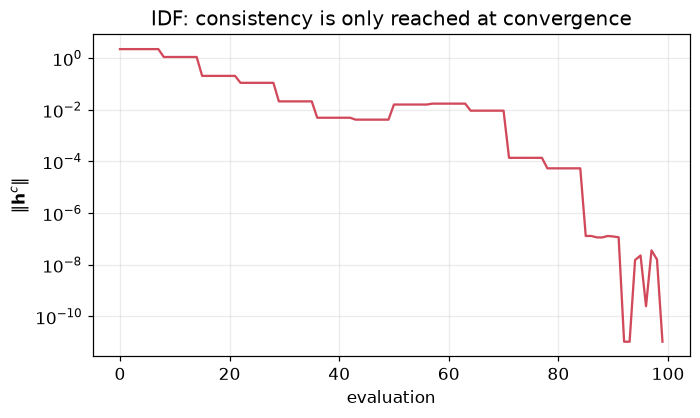

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(np.maximum(idf.history, 1e-16), color=COLORS["idf"], lw=1.5)
ax.set(xlabel="evaluation", ylabel=r"$\|\mathbf{h}^c\|$", title="IDF: consistency is only reached at convergence")
plt.show()

### IDF with a derivative-free optimizer

DFO methods handle equality constraints poorly. The slides use the inequality
$g^c = \|\mathbf{h}^c\| - \varepsilon \le 0$ with a small tolerance $\varepsilon$; we use
$\varepsilon = 10^{-3}$. The search space now has **5** variables instead of 3.

In [7]:
EPS = 1e-3


def idf_blackbox(z):
    z = np.asarray(z, dtype=float)
    try:
        with np.errstate(all="raise"):
            a, b = idf.analyses(z)
    except FloatingPointError:
        return [np.inf, [np.inf, np.inf]]
    hc = np.linalg.norm([z[3] - a, z[4] - b])
    return [z[0] + z[1] + a + b, [z[2] + b - 10.0, hc - EPS]]


reset_counters()
idf = IDF()
tic = time.perf_counter()
z_best, _ = omads_solve(idf_blackbox, Z0, ZLB, ZUB, ["u", "v", "w", "at", "bt"], budget=1500, n_con=2)
a_hat, b_hat = idf.analyses(z_best)
idf_dfo = dict(formulation="IDF", solver="OMADS", f=z_best[0] + z_best[1] + a_hat + b_hat, x=np.round(z_best[:3], 4),
               g=z_best[2] + b_hat - 10.0, consistency=np.linalg.norm([z_best[3] - a_hat, z_best[4] - b_hat]),
               D1_calls=D1.calls - 1, D2_calls=D2.calls - 1, time_s=time.perf_counter() - tic)
idf_dfo

{'formulation': 'IDF',
 'solver': 'OMADS',
 'f': 5.902803474801731,
 'x': array([1.8724, 0.9227, 1.8442]),
 'g': -6.243431379609328,
 'consistency': 0.0008325756490965537,
 'D1_calls': 1501,
 'D2_calls': 1501,
 'time_s': 7.229305100161582}

---
## 4. The scoreboard

Compare the four runs. Read the **discipline-call** columns carefully: that is what a
real MDO study pays for.

In [8]:
board = pd.DataFrame([mdf_slsqp, idf_slsqp, mdf_dfo, idf_dfo]).set_index(["formulation", "solver"])
board

,,f,x,g,consistency,D1_calls,D2_calls,time_s
formulation,solver,,,,,,,
MDF,SLSQP,4.98933,"[1.2465, 0.6488, 7.5782]",2.6672e-11,0,192,192,0.0057722
IDF,SLSQP,4.98933,"[1.2465, 0.6488, 7.5782]",9.90497e-12,1.05446e-11,285,285,0.004428
MDF,OMADS,4.98933,"[1.2463, 0.6488, 7.5779]",-6.58134e-05,0,2948,2948,1.00326
IDF,OMADS,5.9028,"[1.8724, 0.9227, 1.8442]",-6.24343,0.000832576,1501,1501,7.22931


What to notice:

- With a gradient-based solver, MDF and IDF reach the **same** optimum, $f^* \approx 4.989$.
- The costs differ in kind. Every MDF evaluation runs a Newton MDA, i.e. **several sequential**
  runs of each discipline; every IDF evaluation runs each discipline **once**, and the two can
  run in parallel. On this tiny problem the totals are similar; on a real problem, where an MDA
  takes 10-30 discipline runs, IDF's advantage grows.
- With DFO, the formulations stop at different points. The gap comes from the *solver*: in
  IDF, MADS must search a 5-dimensional space and keep $\|\mathbf{h}^c\|$ within $\varepsilon$,
  so it makes less progress for the same budget (the slides discuss exactly this:
  IDF 5.458 vs. MDF 5.006).
- Every MDF evaluation is consistent. An IDF evaluation is only consistent at convergence.

---
## 5. Robustness: what happens when the MDA fails?

In the MDA notebook, Gauss-Seidel **diverged** at $v = 0.3$ (contraction factor $1.61$).
Suppose our MDF code used Gauss-Seidel instead of Newton. We start both formulations at
$\mathbf{x}^{(0)} = [1, 0.3, 1]$ and count how many evaluations end in an MDA failure.

In [9]:
def gauss_seidel_mda(x, u0=(1.0, 4.5), tol=1e-8, max_iter=100):
    u, v, w = x
    b = u0[1]
    for _ in range(max_iter):
        with np.errstate(all="raise"):
            try:
                a = D1(u, v, b)
                b_new = D2(u, w, a)
            except FloatingPointError:
                raise MDAFailure("discipline crashed")
        if not np.isfinite(b_new) or b_new <= 0:
            raise MDAFailure("diverged")
        if abs(b_new - b) < tol:
            if a <= 0:
                raise MDAFailure("converged to the non-physical branch a < 0")
            return np.array([a, b_new])
        b = b_new
    raise MDAFailure("no convergence")


class MDF_GS(MDF):
    def coupling(self, x):
        key = tuple(np.round(x, 12))
        if key not in self.cache:
            self.cache[key] = gauss_seidel_mda(x)
        return self.cache[key]


X_HARD = np.array([1.0, 0.3, 1.0])
reset_counters()
mdf = MDF_GS()
x_gs, _ = omads_solve(mdf_blackbox, X_HARD, LB, UB, ["u", "v", "w"], budget=600, n_con=1)
print(f"MDF with a Gauss-Seidel MDA: {mdf.failures} of 600 evaluations failed; "
      f"best f = {mdf_blackbox(x_gs)[0]:.4f} at x = {np.round(x_gs, 3)}")

reset_counters()
idf = IDF()
z_hard, _ = omads_solve(idf_blackbox, np.r_[X_HARD, 1.0, 1.0], ZLB, ZUB, ["u", "v", "w", "at", "bt"],
                        budget=1500, n_con=2)
print(f"IDF from the same design: best f = {idf_blackbox(z_hard)[0]:.4f}, "
      f"||h_c|| = {idf_blackbox(z_hard)[1][1] + EPS:.1e}  (no MDA, nothing to fail)")

MDF with a Gauss-Seidel MDA: 210 of 600 evaluations failed; best f = 5.0022 at x = [1.243 0.714 7.425]


IDF from the same design: best f = 6.0816, ||h_c|| = 9.9e-04  (no MDA, nothing to fail)


Read both lines carefully, because the lesson is not "IDF wins":

- MDF still found a good design, because MADS simply treats a failed evaluation as a bad
  point and moves on. But about a third of its evaluations were **failed MDAs**: each one
  ran Gauss-Seidel up to 100 sweeps before giving up. With a real CFD/FEA code, that is a
  large amount of wasted computing.
- IDF had **no failures** (there is no MDA to fail), but with a derivative-free solver it made
  less progress in its larger, equality-constrained search space.

Robustness and efficiency pull in different directions. The usual practical answer is a
robust MDA inside MDF (Newton with damping, as in Section 2) or a gradient-based optimizer for
IDF, which handles the consistency constraints well (Section 3).

---
## 6. A modelling pitfall: more than one MDA solution

The slides use the bounds $0 < u, v, w \le 10$. Look at what happens to the MDA as $v \to 0$,
with $u = 1$ and $w = 7.6$. For each $v$ we scan $\hat a$ and find **every** root of the MDA
equation $\hat a = \log u + \log v + \log\big(\mathcal{U}_2(\hat a)\big)$.

In [10]:
def all_mda_roots(x, grid=np.r_[-np.logspace(1, -4, 4000), np.logspace(-4, 1, 4000)]):
    u, v, w = x
    roots = []
    with np.errstate(all="ignore"):
        F = grid - (np.log(u) + np.log(v) + np.log(1 / u + 1 / w + 1 / grid))
    for i in range(len(grid) - 1):
        if np.isfinite(F[i]) and np.isfinite(F[i + 1]) and F[i] * F[i + 1] < 0:
            a = 0.5 * (grid[i] + grid[i + 1])
            b = 1 / u + 1 / w + 1 / a
            roots.append((a, b, u + v + a + b))
    return roots


rows = []
for v in [1.0, 0.3, 0.1, 1e-2, 1e-3, 1e-4]:
    for a, b, f in all_mda_roots((1.0, v, 7.6)):
        rows.append(dict(v=v, a=a, b=b, f=f, branch="a > 0" if a > 0 else "a < 0"))
pd.DataFrame(rows)

,v,a,b,f,branch
0,1,-1.20336,0.300572,1.09721,a < 0
1,1,0.842087,2.31911,5.16119,a > 0
2,0.3,-1.76985,0.566561,0.0967066,a < 0
3,0.3,0.297847,4.489,6.08685,a > 0
4,0.1,-2.59555,0.746304,-0.749244,a < 0
5,0.1,0.100607,11.0713,12.2719,a > 0
6,0.01,-4.69671,0.918664,-2.76804,a < 0
7,0.01,0.010026,100.873,101.893,a > 0
8,0.001,-6.92764,0.98723,-4.93941,a < 0
9,0.001,0.000999138,1001.99,1003,a > 0


Even at $v = 1$ the MDA has a **second solution** with $\hat a < 0$, and on that branch
$f \to -\infty$ as $v \to 0$. Watch what MDF does when we remove the safeguard from Section 2
and let the warm-started Newton MDA return whichever solution it finds:

In [11]:
reset_counters()
mdf = MDF(physical_branch_only=False)
res_raw = minimize(mdf.f, X0, method="SLSQP", bounds=list(zip(LB, UB)),
                   constraints=[{"type": "ineq", "fun": lambda x: -mdf.g(x)}], options={"ftol": 1e-10})
a_raw, b_raw = mdf.coupling(res_raw.x)
print(f"MDF without the safeguard: f = {res_raw.fun:.4f} at x = {np.round(res_raw.x, 4)}, "
      f"a = {a_raw:.3f}, b = {b_raw:.3f}")

MDF without the safeguard: f = -4.9749 at x = [1.0297e+00 1.0000e-03 9.0621e+00], a = -6.943, b = 0.937


The optimizer found a "better" design with $f < 0$ by driving $v$ to its lower bound on the
non-physical branch. Nothing crashed and the MDA converged: only checking the coupling
variables reveals the problem. Lessons:

1. An MDA can have several solutions, and which one you get depends on the **starting point**
   of the MDA solver. MDF silently inherits that choice.
2. The problem as stated is **unbounded** below. All the other solutions in this notebook are
   **local** optima on the physically meaningful branch ($\hat a > 0$). In a real study you
   would fix the model, for example with a tighter lower bound on $v$ or a constraint $\hat a > 0$.
3. IDF was protected here by its **bounds on the targets** ($a^t \ge 10^{-3}$): a consistent
   IDF point cannot have $\hat a < 0$. Bounds on coupling targets are part of the model.

---
## Exercises

1. **Budget sensitivity.** Rerun MDF and IDF with OMADS for budgets of 200, 600 and 1500
   evaluations. Plot the final $f$ against the number of *discipline calls*. Which formulation
   is more efficient per discipline call?
2. **Cold vs. warm start.** Change `MDF.coupling` to always start Newton from $[1, 1]$. How
   many more discipline calls does SLSQP need?
3. **Parallel IDF.** Assume each discipline call takes 1 hour and you have 2 machines. Estimate
   the wall-clock time of each run in the scoreboard.
4. **Fix the model.** Add the constraint $\hat a \ge 0.05$ to both formulations. Does the
   optimum change? Does the unbounded branch disappear?

---
## Takeaways

1. MDF hides the coupling inside an MDA: small optimization problem, consistent iterates,
   but every evaluation costs a converged MDA and inherits its failures.
2. IDF moves consistency into the optimizer: more variables and equality constraints, but
   one run of each discipline per evaluation, in parallel, with no MDA to fail.
3. At convergence both have the **same optima**; differences in practice come from the solver
   and its budget.
4. Always check what your MDA converged to: coupled systems can have several solutions.